In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh_tridiagonal

In [2]:
# Parameters
a = 1.0
V0 = 20.0
L = 6
dx = 0.01

x = np.arange(-L, L + dx/2, dx)

# Define potential
V = np.where(np.abs(x) < a, 0.0, V0)

# Construct Hamiltonian matrix
N = len(x) - 2
diagonal = 2/dx**2 + V[1:-1]
off_diagonal = np.full(N-1, -1/dx**2)

# Calculate eigenvalues and eigenvectors
energies, wavefunctions = eigh_tridiagonal(diagonal, off_diagonal, select='i', select_range=(0, 5))
print("Numerical energy eigenvalues:")
for i, E in enumerate(energies):
    print(f"State {i+1}: {E:.6f}")

# Add boundary points to wavefunctions
psi = np.zeros((len(x), wavefunctions.shape[1]))
psi[1:-1, :] = wavefunctions

# Normalize wavefunctions
for i in range(psi.shape[1]):
    norm = np.sqrt(np.trapezoid(psi[:, i]**2, x))
    psi[:, i] /= norm

Numerical energy eigenvalues:
State 1: 1.639320
State 2: 6.441142
State 3: 13.889777
State 4: 20.278135
State 5: 20.401786
State 6: 21.082760


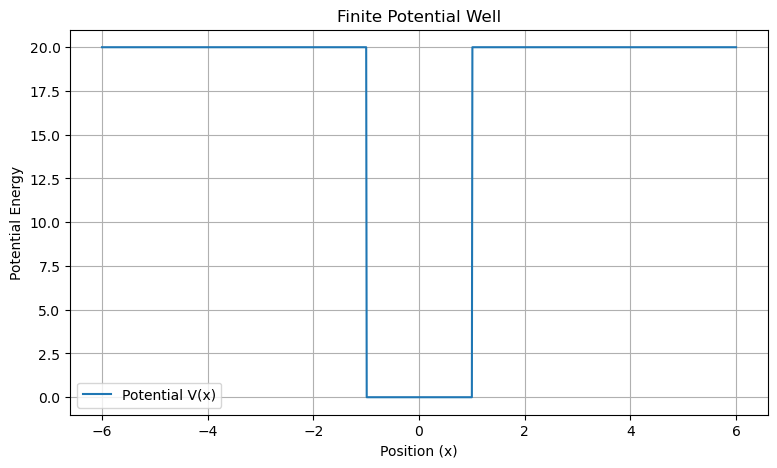

In [3]:
# Plot potential
plt.figure(figsize=(9, 5))
plt.plot(x, V, label="Potential V(x)")
plt.xlabel("Position (x)")
plt.ylabel("Potential Energy")
plt.title("Finite Potential Well")
plt.grid()
plt.legend()
plt.show()

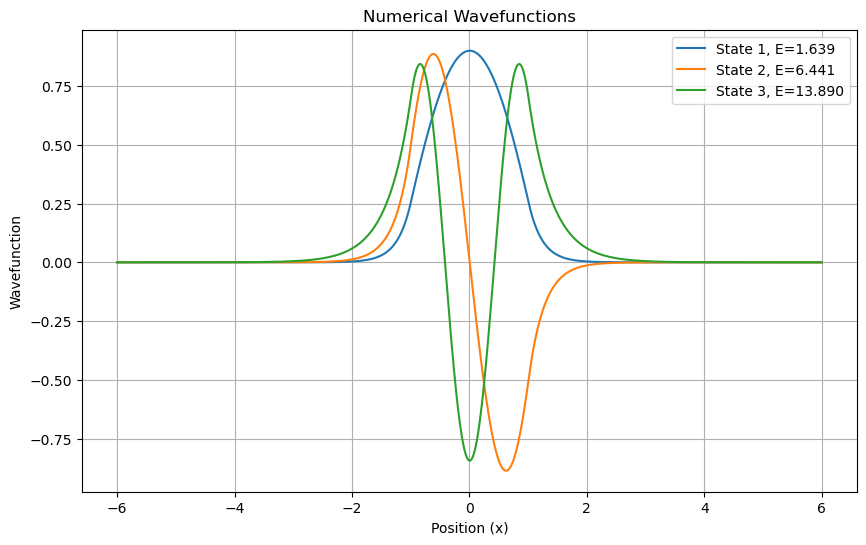

In [4]:
# Plot wavefunctions
plt.figure(figsize=(10, 6))
for i in range(3):
    plt.plot(x,psi[:, i],label=f"State {i+1}, E={energies[i]:.3f}")
plt.xlabel("Position (x)")
plt.ylabel("Wavefunction")
plt.title("Numerical Wavefunctions")
plt.grid()
plt.legend()
plt.show()

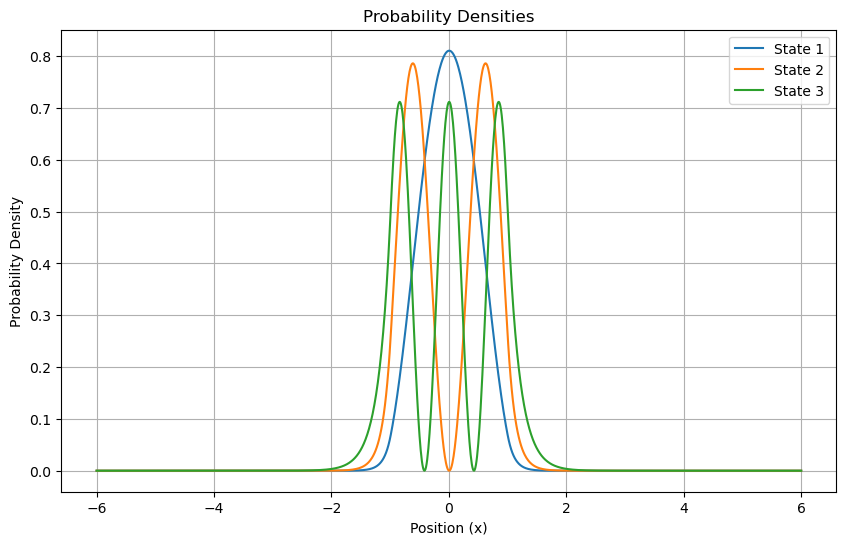

In [5]:
# Plot probability densities
plt.figure(figsize=(10, 6))
for i in range(3):
    plt.plot(x,psi[:, i]**2,label=f"State {i+1}")
plt.xlabel("Position (x)")
plt.ylabel("Probability Density")
plt.title("Probability Densities")
plt.grid()
plt.legend()
plt.show()

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def finite_well(x, a, V0):
    V = np.zeros(len(x))
    V[np.abs(x) <= a] = -V0
    return V

In [7]:
def bisection(f, left, right, tol=1e-10):
    f_left = f(left)
    while right - left > tol:
        mid = (left + right)/2
        f_mid = f(mid)
        if f_left*f_mid < 0:
            right = mid
        else:
            left = mid
            f_left = f_mid
    return (left + right)/2

In [8]:
def find_eigenvalues(a, V0):
    z0 = a*np.sqrt(V0)
    energies = []
    states = []
    n = 0
    while n*np.pi < z0:
        # Even state
        left = n*np.pi + 1e-8
        right = min(n*np.pi + np.pi/2 - 1e-8, z0 - 1e-8)
        if left < right:
            def f_even(z):
                return z*np.tan(z) - np.sqrt(z0**2-z**2)
            if f_even(left)*f_even(right) < 0:
                z = bisection(f_even, left, right)
                E = z**2/a**2 - V0
                energies.append(E)
                states.append("Even")
        # Odd state
        left = n*np.pi + np.pi/2 + 1e-8
        right = min((n+1)*np.pi - 1e-8, z0 - 1e-8)
        if left < right:
            def f_odd(z):
                return -z/np.tan(z) - np.sqrt(z0**2-z**2)
            if f_odd(left)*f_odd(right) < 0:
                z = bisection(f_odd, left, right)
                E = z**2/a**2 - V0
                energies.append(E)
                states.append("Odd")
        n += 1
    return np.array(energies), states

In [9]:
a = 1
V0 = 10

energies, states = find_eigenvalues(a, V0)

for i in range(len(energies)):

    print("State:", i+1)
    print("Parity:", states[i])
    print("Energy:", energies[i])
    print()

State: 1
Parity: Even
Energy: -8.592785275302605

State: 2
Parity: Odd
Energy: -4.62419408617177

State: 3
Parity: Even
Energy: -0.004019262584534999



In [10]:
def wavefunction(x, a, V0, E, parity):
    k = np.sqrt(E+V0)
    kappa = np.sqrt(-E)
    psi = np.zeros(len(x))
    inside = np.abs(x) <= a
    outside = np.abs(x) > a
    if parity == "Even":
        psi[inside] = np.cos(k*x[inside])
        psi[outside] = (np.cos(k*a)*np.exp(-kappa*(np.abs(x[outside])-a)))

    else:
        psi[inside] = np.sin(k*x[inside])
        psi[outside] = (np.sign(x[outside])*np.sin(k*a)* np.exp(-kappa*(np.abs(x[outside])-a)))

    # Normalisation
    norm = np.sqrt(np.trapz(psi**2, x))
    psi = psi/norm
    return psi

C:\Users\hp\AppData\Local\Temp\ipykernel_11200\2110347005.py:16: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  norm = np.sqrt(np.trapz(psi**2, x))


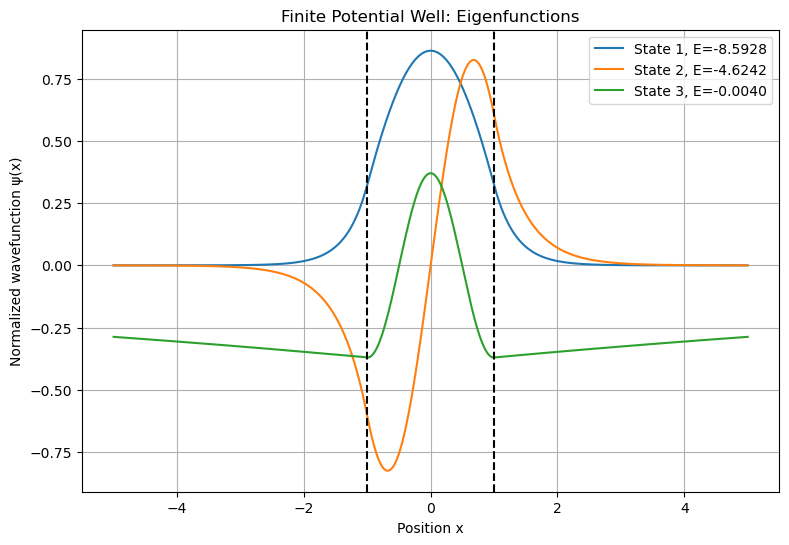

In [11]:
x = np.linspace(-5*a, 5*a, 2000)
plt.figure(figsize=(9,6))
for i in range(len(energies)):
    psi = wavefunction(x, a, V0, energies[i], states[i])
    plt.plot(x, psi, label=f"State {i+1}, E={energies[i]:.4f}")
plt.xlabel("Position x")
plt.ylabel("Normalized wavefunction ψ(x)")
plt.title("Finite Potential Well: Eigenfunctions")
plt.axvline(-a, linestyle="--", color="black")
plt.axvline(a, linestyle="--", color="black")
plt.grid()
plt.legend()
plt.show()

Effect of changing width and depth

In [12]:
widths = [0.5, 1.0, 1.5, 2.0]
depths = [5, 10, 15, 20]
for a in widths:
    for V0 in depths:
        energies, states = find_eigenvalues(a, V0)
        print("Width =", 2*a, "Depth =", V0)
        print("Eigenvalues =", energies)
        print()

Width = 1.0 Depth = 5
Eigenvalues = [-2.51443098]

Width = 1.0 Depth = 10
Eigenvalues = [-6.49022313e+00 -1.05249444e-03]

Width = 1.0 Depth = 15
Eigenvalues = [-10.8584187   -1.19928849]

Width = 1.0 Depth = 20
Eigenvalues = [-15.4100185   -3.72570448]

Width = 2.0 Depth = 5
Eigenvalues = [-3.85250463 -0.93142612]

Width = 2.0 Depth = 10
Eigenvalues = [-8.59278528e+00 -4.62419409e+00 -4.01926258e-03]

Width = 2.0 Depth = 15
Eigenvalues = [-13.45285384  -8.97284499  -2.38506994]

Width = 2.0 Depth = 20
Eigenvalues = [-18.36051985 -13.55812004  -6.10846702]

Width = 3.0 Depth = 5
Eigenvalues = [-4.35601881 -2.5229684  -0.13694134]

Width = 3.0 Depth = 10
Eigenvalues = [-9.25533914e+00 -7.06629452e+00 -3.62404845e+00 -8.42448823e-03]

Width = 3.0 Depth = 15
Eigenvalues = [-14.20393517 -11.84340901  -8.02361552  -3.06709789]

Width = 3.0 Depth = 20
Eigenvalues = [-19.17096981 -16.7033028  -12.66685517  -7.24076022  -1.10428471]

Width = 4.0 Depth = 5
Eigenvalues = [-4.59012996 -3.38953001